In [2]:
import pandas as pd

In [3]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_METRIC_NUMBER = r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?"
_FIT_HEADER = re.compile(r"Round (\d+) local fit metrics: ")


def _load_client_fit_metrics(log_dir, metric_names):
    """Per-client validation metrics from ``Round N local fit metrics`` lines."""
    log_dir = Path(log_dir)
    patterns = {
        name: re.compile(rf"'{re.escape(name)}': ({_METRIC_NUMBER})")
        for name in metric_names
    }
    rows = []
    for log_path in sorted(log_dir.glob("client_*.log")):
        client_id = int(log_path.stem.rsplit("_", 1)[-1])
        by_round = {}
        with log_path.open(encoding="utf-8", errors="replace") as file:
            for line in file:
                header = _FIT_HEADER.search(line)
                if header is None:
                    continue
                values = {}
                for name, pattern in patterns.items():
                    match = pattern.search(line)
                    if match is None:
                        break
                    values[name] = float(match.group(1))
                else:
                    by_round[int(header.group(1))] = values
        for server_round, values in by_round.items():
            rows.append({"client": client_id, "round": server_round, **values})
    if not rows:
        raise FileNotFoundError(f"No client fit metrics in {log_dir}")
    return pd.DataFrame(rows)


def plot_client_deviation(
    log_dir,
    metrics_df=None,
    metric_names=("val_loss", "val_accuracy"),
):
    """Server metric against the client range on each round.

    The band is the best-to-worst client, the dashed line is the unweighted
    client mean, and the marked line is the aggregated global-model metric
    from ``metrics.csv`` (loss is the weighted mean, accuracy/F1 come from
    the pooled confusion matrix).
    """
    log_dir = Path(log_dir)
    if metrics_df is None:
        metrics_df = pd.read_csv(log_dir / "metrics.csv")
    metric_names = tuple(metric_names)
    clients = _load_client_fit_metrics(log_dir, metric_names)

    missing = [name for name in metric_names if name not in metrics_df.columns]
    if missing:
        raise KeyError(f"metrics.csv has no columns: {missing}")

    summary = (
        clients.groupby("round")[list(metric_names)]
        .agg(["min", "max", "mean"])
    )
    rounds = summary.index.to_numpy()
    span = int(rounds[-1] - rounds[0])
    step = 3 if span <= 70 else 5
    ticks = list(range(int(rounds[0]), int(rounds[-1]) + 1, step))
    if ticks[-1] != int(rounds[-1]):
        ticks.append(int(rounds[-1]))

    band_colors = {
        "val_loss": "#f6d2cc",
        "val_accuracy": "#d5e8f7",
    }
    fallback = ("#f6d2cc", "#d5e8f7", "#d9f0df", "#f8e3c4")

    fig, axes = plt.subplots(
        len(metric_names),
        1,
        figsize=(12, 3.8 * len(metric_names)),
        squeeze=False,
    )
    server = metrics_df.set_index("round")
    for index, (ax, name) in enumerate(zip(axes[:, 0], metric_names)):
        common = summary.index.intersection(server.index)
        band = summary.loc[common, name]
        global_metric = server.loc[common, name].astype(float)
        color = band_colors.get(name, fallback[index % len(fallback)])
        adjective = "Серверный" if name.endswith("loss") else "Серверная"

        ax.fill_between(
            common,
            band["min"],
            band["max"],
            color=color,
            linewidth=0,
            label="диапазон клиентов (best-worst)",
            zorder=1,
        )
        ax.plot(
            common,
            band["mean"],
            color="#4d4d4d",
            linestyle="--",
            linewidth=1.2,
            label="среднее по клиентам",
            zorder=2,
        )
        ax.plot(
            common,
            global_metric,
            color="black",
            marker="o",
            markersize=3.5,
            linewidth=1.3,
            label=f"server {name}",
            zorder=3,
        )
        ax.set_title(f"{adjective} {name} vs клиенты")
        ax.set_ylabel(name)
        ax.set_xlim(common.min(), common.max())
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"Р{tick}" for tick in ticks])
        ax.tick_params(labelbottom=True)
        ax.legend(
            loc="upper right" if name.endswith("loss") else "upper left",
            frameon=True,
            fontsize=9,
        )
        if "accuracy" in name or name.endswith("f1"):
            ax.set_ylim(bottom=0.0)

    axes[-1, 0].set_xlabel("Раунд")
    fig.tight_layout()
    plt.show()


In [5]:
def plot_client_boxplot(
    log_dir,
    metrics_df=None,
    metric_names=("val_loss", "val_accuracy"),
):
    """Box plot of the client metric on each round, with the global model.

    Each box is one round: the orange line is the client median, the box is
    the interquartile range, whiskers cover points within 1.5 IQR, and circles
    are outliers. The black line is the aggregated global-model metric.
    """
    log_dir = Path(log_dir)
    if metrics_df is None:
        metrics_df = pd.read_csv(log_dir / "metrics.csv")
    metric_names = tuple(metric_names)
    clients = _load_client_fit_metrics(log_dir, metric_names)

    missing = [name for name in metric_names if name not in metrics_df.columns]
    if missing:
        raise KeyError(f"metrics.csv has no columns: {missing}")

    rounds = np.sort(clients["round"].unique())
    span = int(rounds[-1] - rounds[0])
    step = 3 if span <= 70 else 5
    ticks = list(range(int(rounds[0]), int(rounds[-1]) + 1, step))
    if ticks[-1] != int(rounds[-1]):
        ticks.append(int(rounds[-1]))

    fig, axes = plt.subplots(
        len(metric_names),
        1,
        figsize=(12, 3.8 * len(metric_names)),
        squeeze=False,
    )
    server = metrics_df.set_index("round")
    for ax, name in zip(axes[:, 0], metric_names):
        common = [int(rnd) for rnd in rounds if rnd in server.index]
        series = [
            clients.loc[clients["round"] == rnd, name].to_numpy()
            for rnd in common
        ]
        ax.boxplot(
            series,
            positions=common,
            widths=0.7,
            manage_ticks=False,
            boxprops={"color": "black", "linewidth": 0.8},
            whiskerprops={"color": "black", "linewidth": 0.8},
            capprops={"color": "black", "linewidth": 0.8},
            medianprops={"color": "#ff7f0e", "linewidth": 1.4},
            flierprops={
                "marker": "o",
                "markerfacecolor": "none",
                "markeredgecolor": "black",
                "markersize": 3.5,
                "linestyle": "none",
            },
        )
        global_metric = server.loc[common, name].astype(float)
        ax.plot(
            common,
            global_metric,
            color="black",
            marker="o",
            markersize=2.2,
            linewidth=1.0,
            label=f"server {name}",
            zorder=3,
        )
        adjective = "Серверный" if name.endswith("loss") else "Серверная"
        ax.set_title(f"{adjective} {name} vs клиенты")
        ax.set_ylabel(name)
        ax.set_xlim(common[0] - 0.8, common[-1] + 0.8)
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"Р{tick}" for tick in ticks])
        ax.tick_params(labelbottom=True)
        ax.legend(
            loc="upper right" if name.endswith("loss") else "upper left",
            frameon=True,
            fontsize=9,
        )
        if "accuracy" in name or name.endswith("f1"):
            ax.set_ylim(bottom=0.0)

    axes[-1, 0].set_xlabel("Раунд")
    fig.tight_layout()
    plt.show()

In [3]:
metrics = pd.read_csv('/app/logs/cifar100_federated_resize224_no_aug/metrics.csv')
metrics[['test_accuracy', 'test_f1', 'test_image_accuracy', 'test_image_f1']]

,test_accuracy,test_f1,test_image_accuracy,test_image_f1
0,0.0146,0.007434,0.0146,0.007434
1,0.1246,0.100599,0.1246,0.100599
2,0.2860,0.253424,0.2860,0.253424
3,0.3997,0.377868,0.3997,0.377868
4,0.4902,0.473496,0.4902,0.473496
...,...,...,...,...
95,0.8418,0.842229,0.8418,0.842229
96,0.8422,0.842714,0.8422,0.842714
97,0.8400,0.840437,0.8400,0.840437
98,0.8417,0.842204,0.8417,0.842204


In [3]:
metrics = pd.read_csv('/app/logs/exp_new_aug_20261004_no_blur_noise/metrics.csv')
metrics[['test_accuracy', 'test_f1', 'test_image_accuracy', 'test_image_f1']]

,test_accuracy,test_f1,test_image_accuracy,test_image_f1
0,0.386084,0.343710,0.368932,0.334912
1,0.480259,0.455067,0.495146,0.469683
2,0.505016,0.482403,0.553398,0.538111
3,0.560000,0.549811,0.553398,0.544703
4,0.537702,0.517287,0.563107,0.541493
...,...,...,...,...
95,0.644304,0.628758,0.699029,0.681223
96,0.648867,0.632334,0.708738,0.689083
97,0.651715,0.636826,0.737864,0.715142
98,0.650712,0.635414,0.728155,0.706649


In [5]:
metrics.columns

Index(['round', 'lr', 'swa_test_accuracy', 'swa_test_f1',
       'swa_test_image_accuracy', 'swa_test_image_f1',
       'swa_test_image_precision', 'swa_test_image_recall', 'swa_test_loss',
       'swa_test_precision', 'swa_test_recall', 'swa_val_accuracy',
       'swa_val_f1', 'swa_val_image_accuracy', 'swa_val_image_f1',
       'swa_val_image_precision', 'swa_val_image_recall', 'swa_val_loss',
       'swa_val_precision', 'swa_val_recall', 'test_accuracy', 'test_f1',
       'test_image_accuracy', 'test_image_f1', 'test_image_precision',
       'test_image_recall', 'test_loss', 'test_precision', 'test_recall',
       'train_accuracy', 'train_f1', 'train_image_accuracy', 'train_image_f1',
       'train_image_precision', 'train_image_recall', 'train_loss',
       'train_precision', 'train_recall', 'val_accuracy', 'val_f1',
       'val_image_accuracy', 'val_image_f1', 'val_image_precision',
       'val_image_recall', 'val_loss', 'val_precision', 'val_recall'],
      dtype='str')

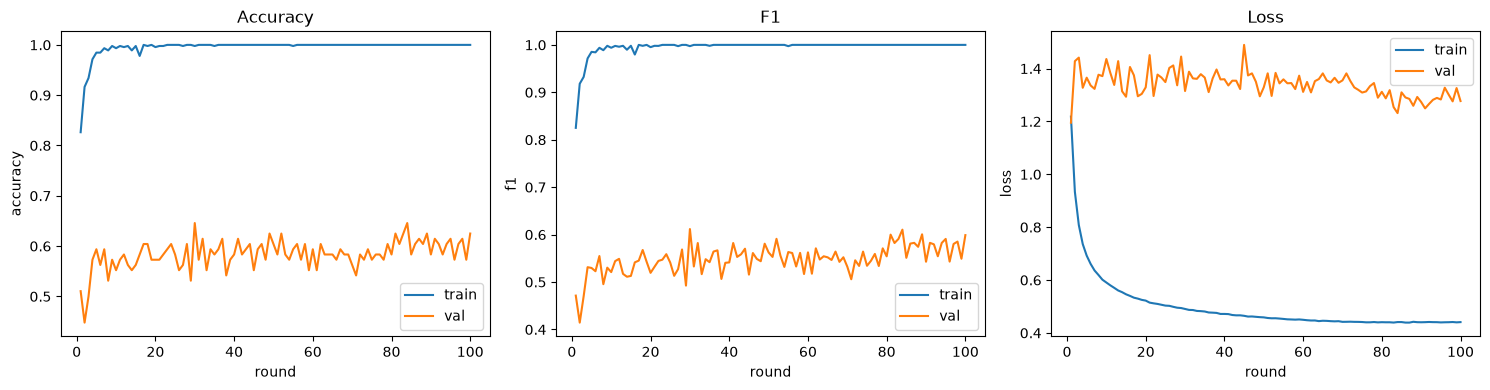

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

def _col(*candidates):
    return next((c for c in candidates if c in metrics.columns), None)

panels = [
    ('Accuracy', _col('train_image_accuracy', 'train_eval_image_accuracy'), _col('val_image_accuracy')),
    ('F1', _col('train_image_f1', 'train_eval_image_f1'), _col('val_image_f1')),
    ('Loss', _col('train_eval_loss', 'train_loss'), _col('val_loss')),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, train_col, val_col) in zip(axes, panels):
    if train_col is not None:
        sns.lineplot(x='round', y=train_col, data=metrics, label='train', ax=ax)
    if val_col is not None:
        sns.lineplot(x='round', y=val_col, data=metrics, label='val', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('round')
    ax.set_ylabel(title.lower())
fig.tight_layout()
plt.show()

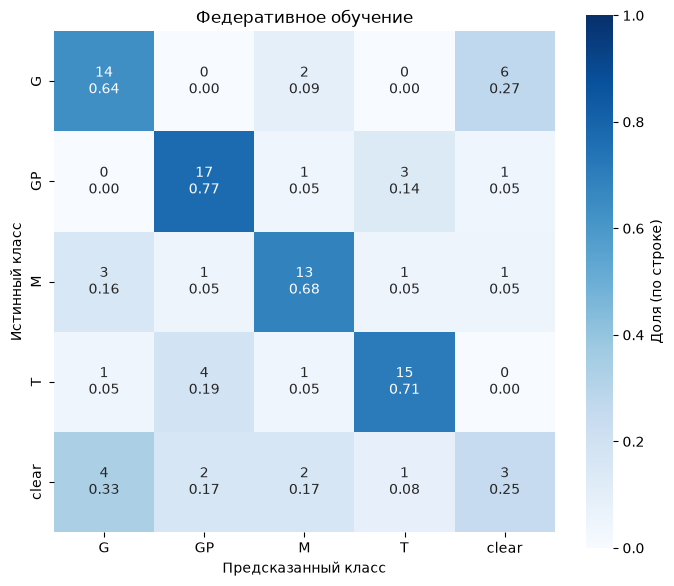

In [8]:
import ast
import re
from pathlib import Path

import numpy as np

log_dir = Path('/app/logs/exp_new_aug_20261004_no_blur_noise')
class_names = ['G', 'GP', 'M', 'T', 'clear']

def parse_cm(encoded):
    n_classes, values = encoded.split('|', 1)
    return np.fromstring(values, sep=',').reshape(int(n_classes), int(n_classes))

pattern = re.compile(r"Round (\d+) local fit metrics: (\{.*\})")
by_round = {}
for log_path in sorted(log_dir.glob('client_*.log')):
    for match in pattern.finditer(log_path.read_text(errors='replace')):
        record = ast.literal_eval(match.group(2))
        by_round.setdefault(int(match.group(1)), []).append(
            parse_cm(record['val_image_confusion_matrix'])
        )

best_round = int(metrics.loc[metrics['val_f1'].idxmax(), 'round'])
cm = np.sum(by_round[best_round], axis=0)
row_sums = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
annot = np.array([
    [f"{int(count)}\n{share:.2f}" for count, share in zip(row, nrow)]
    for row, nrow in zip(cm, cm_norm)
])

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_norm,
    annot=annot,
    fmt='s',
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues',
    square=True,
    vmin=0.0,
    vmax=1.0,
    cbar_kws={'label': 'Доля (по строке)'},
    ax=ax,
)
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
# ax.set_title(f'val, image, round {best_round}')
ax.set_title('Федеративное обучение')
fig.tight_layout()
plt.show()

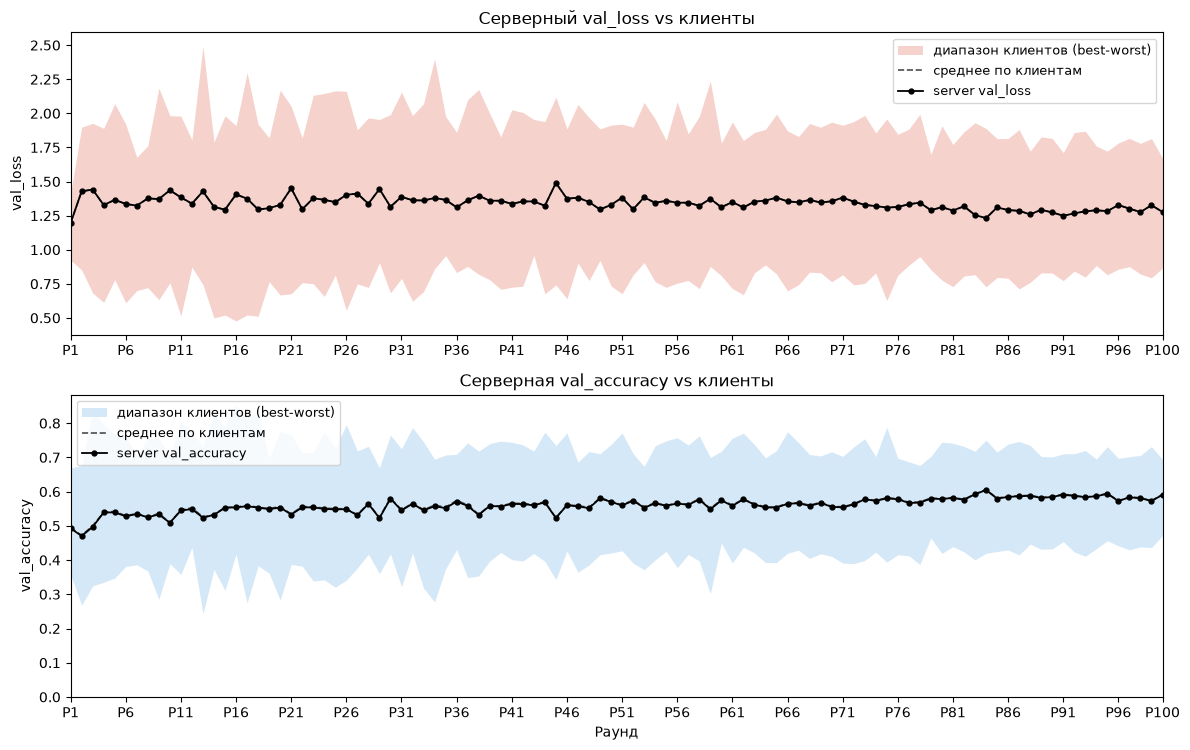

In [4]:
plot_client_deviation("/app/logs/exp_new_aug_20261004_no_blur_noise")

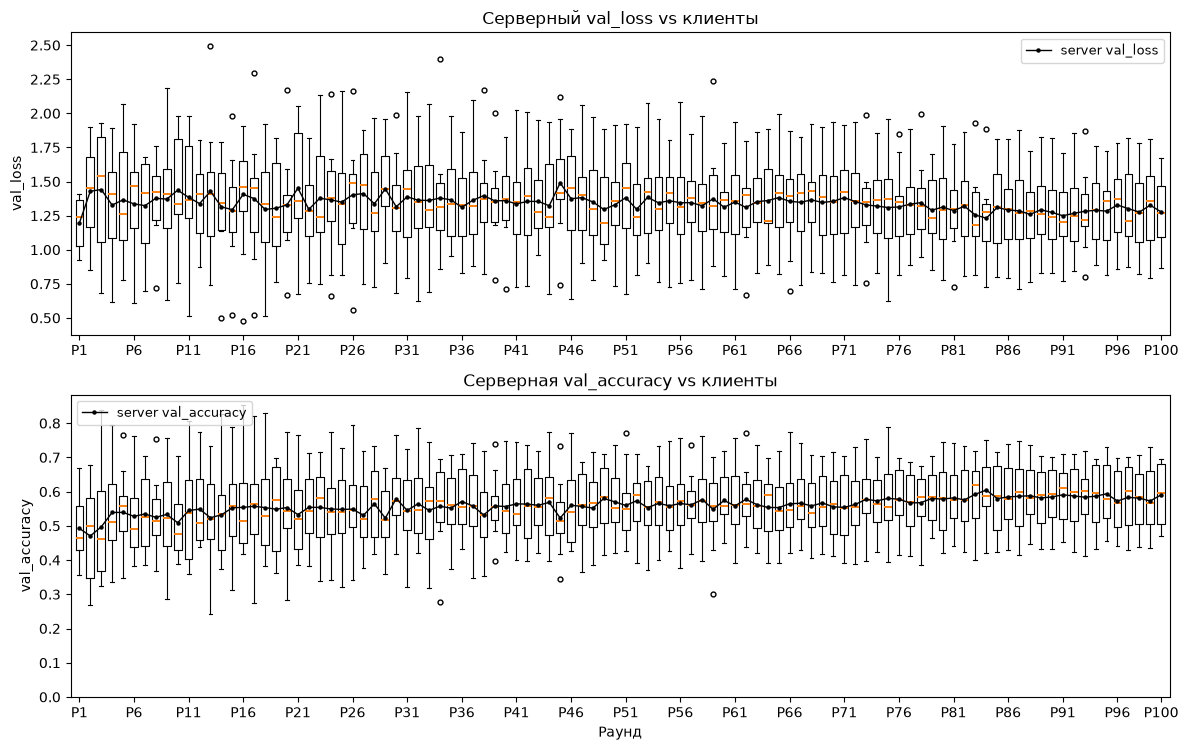

In [6]:
plot_client_boxplot("/app/logs/exp_new_aug_20261004_no_blur_noise")

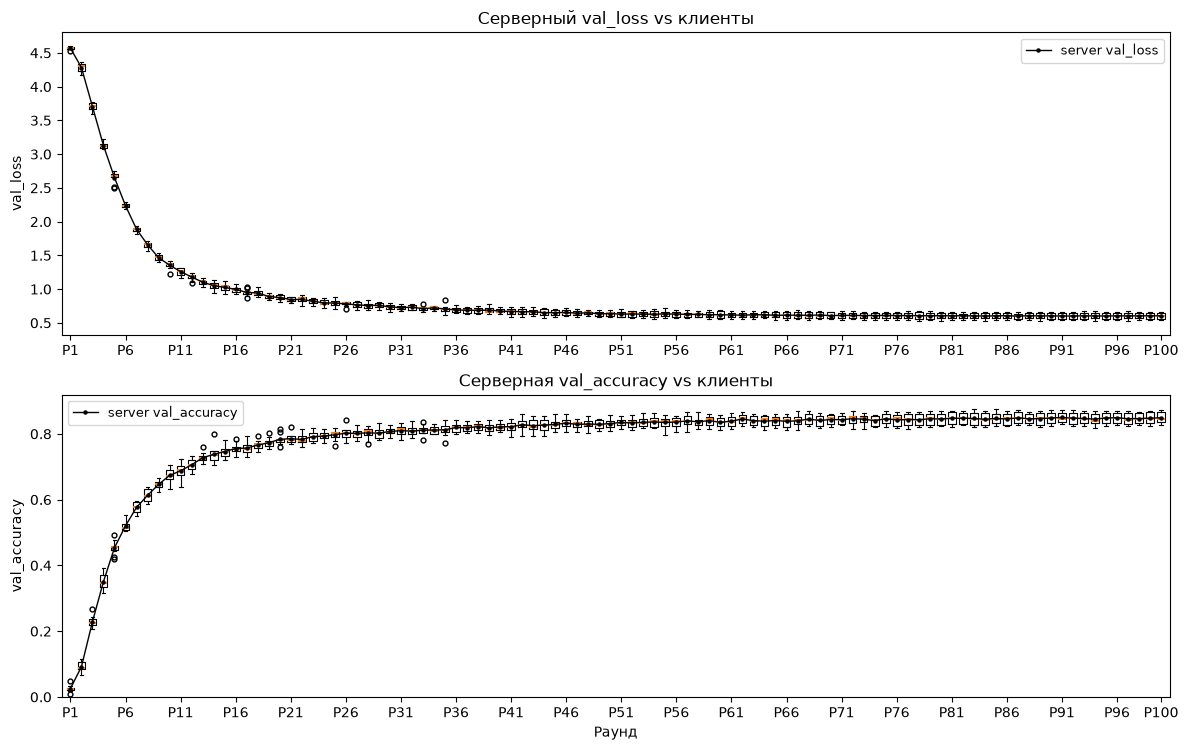

In [7]:
plot_client_boxplot("/app/logs/cifar100_federated_resize224_no_aug")